# Leave-One-Animal-Out Genotype Classification (WT / Grin2a-HET / Grin2a-KO)



In [1]:
import os
import re
import json
import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from scipy.signal import butter, lfilter, welch
from collections import Counter, defaultdict

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)


TensorFlow: 2.10.1


In [2]:
# ============================== GPU CHECK / SETUP ============================
import platform

gpus = tf.config.list_physical_devices("GPU")
if len(gpus) == 0:
    is_windows = platform.system() == "Windows"
    tf_major, tf_minor = (int(x) for x in tf.__version__.split(".")[:2])
    tf_too_new_for_native_windows = (tf_major, tf_minor) >= (2, 11)

    if is_windows and tf_too_new_for_native_windows:
        raise ImportError(
            f"No GPU visible to TensorFlow {tf.__version__} on native Windows. This is NOT "
            "a driver/CUDA problem -- TensorFlow >=2.11 dropped native Windows GPU support "
            "entirely (Google's own limitation, not fixable via CUDA/cuDNN install). Options:\n"
            "  A) Run this notebook in Google Colab with a GPU runtime instead (Runtime -> "
            "Change runtime type -> GPU) -- simplest, no local setup.\n"
            "  B) Downgrade locally: pip install \"tensorflow==2.10.*\" with CUDA 11.2 + "
            "cuDNN 8.1 -- TF 2.10 still supports native Windows GPU directly.\n"
            "  C) Use WSL2 (Google's recommended path for current TF + Windows GPU): install "
            "Ubuntu via WSL2, then inside it `pip install tensorflow[and-cuda]`.\n"
            "  D) Non-NVIDIA GPU: `pip install tensorflow-cpu==2.10 tensorflow-directml-plugin` "
            "(native Windows, no WSL2, but slower than CUDA and some ops silently fall back to CPU)."
        )
    else:
        raise ImportError(
            "No GPU access. In Colab: Runtime -> Change runtime type -> Hardware "
            "accelerator -> GPU. On a local machine: check your CUDA/cuDNN install "
            "matches this TensorFlow version, and that the GPU build of tensorflow "
            "is what's actually installed."
        )
print(f"GPU(s) detected: {[g.name for g in gpus]}")

for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

USE_MIXED_PRECISION = False  # DISABLED: this is what caused your AdamW crash.

if USE_MIXED_PRECISION:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision enabled (mixed_float16).")


GPU(s) detected: ['/physical_device:GPU:0']


In [3]:
# ============================== CONFIG =======================================
data_path = r"D:\UMICH\Deep_Learning\CNN_samples\ML_Samples"
OUT_DIR   = r"D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13"
os.makedirs(OUT_DIR, exist_ok=True)

sf         = 20000   # original sampling frequency
target_sf  = 1000    # downsampled frequency
samples_per_minute = sf * 60

WINDOW_SIZE = 1000    # samples at target_sf per window -- 1 Hz frequency

STRIDE      = 550
REFERENCE_CHANNEL = 14   # skipped, matches your original code

BAND_DEFINITIONS = {

    "theta":      (4, 12),      # TBO
    "beta":       (12, 25),
    "low_gamma":  (30, 59),
    "high_gamma": (61, 100),    # GBO (both gamma bands together)
    "gamma": (30, 100),    # GBO (both gamma bands together)
    "hfo":        (120, 200),   # HFO -- adjust bounds to your definition
}

EPOCHS     = 200       

BATCH_SIZE = 64     


MODELS_TO_RUN = ["RNN", "BiRNN", "GRU-RNN", "CNN_LSTM", "CNN"]

RESULTS_CSV = os.path.join(OUT_DIR, "per_animal_per_model_LOGO_results.csv")

LABEL_MAP = {"WT": 0, "HET": 1, "KO": 2}
INV_LABEL_MAP = {v: k for k, v in LABEL_MAP.items()}

print(f"OUT_DIR: {OUT_DIR}")
print(f"Models to run: {MODELS_TO_RUN}")
print(f"Results will be saved/resumed at: {RESULTS_CSV}")


OUT_DIR: D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13
Models to run: ['RNN', 'BiRNN', 'GRU-RNN', 'CNN_LSTM', 'CNN']
Results will be saved/resumed at: D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13\per_animal_per_model_LOGO_results.csv


In [4]:
# ===================== PREPROCESSING (unchanged from your notebook) =========

def filter_data(data, low, high, sf, order=2):
    nyq = sf / 2
    low = low / nyq
    high = high / nyq
    b, a = butter(order, [low, high], btype="bandpass")
    return lfilter(b, a, data)


def downsample_data(data, sf, target_sf):
    """Always calculates the downsampling factor as an integer and applies
       decimation in steps of up to 10 to avoid excessive decimation in one
       step (which can cause aliasing)."""
    factor = int(sf / target_sf)
    if factor < 1:
        raise ValueError("Target sampling frequency must be less than original sampling frequency.")
    data_down = data
    while factor > 1:
        step_factor = min(factor, 10)
        data_down = signal.decimate(data_down, step_factor, ftype="fir")
        sf = sf / step_factor
        factor = int(sf / target_sf)
    return data_down, int(sf)


f0 = 60.0
w0 = f0 / (target_sf / 2)
Q = 30
notch_b, notch_a = signal.iirnotch(w0, Q)

print("Preprocessing functions ready: filter_data (band-pass) -> downsample_data -> notch filter.")


Preprocessing functions ready: filter_data (band-pass) -> downsample_data -> notch filter.


In [5]:
# ===================== FILE MANIFEST + ANIMAL ID ============================

file_paths_WT = [
    data_path + r"/2024-06-03__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5",
    data_path + r"/2024-06-03__Slice2_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-06__Slice1_WT_mPFC_Baseline__0006.h5",
    data_path + r"/2024-06-06__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0002.h5",
    data_path + r"/2024-06-06__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-11__Slice1_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-11__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0005.h5",
    data_path + r"/2024-06-11__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-11__Slice4_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-07-09mPFC_Slice2_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_WT_Vehicle_.h5",
    data_path + r"/2024-07-10mPFC_Slice1_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_WT_Vehicle_.h5",
    data_path + r"/2024-07-22__Slice1_AAV1_SST_Chr2_eYFP_mPFC_WT_Baseline__0003.h5",
    data_path + r"/2024-07-22__Slice5_AAV1_SST_Chr2_eYFP_mPFC_WT_Baseline__0003.h5",
    data_path + r"/2024-07-22__Slice7_AAV1_SST_Chr2_eYFP_mPFC_WT_Baseline__0001.h5",
    data_path + r"/2024-07-23__Slice2_AAV1_SST_Chr2_eYFP_mPFC_WT_Baseline__0003.h5",
]

file_paths_HET = [
    data_path + r"/2024-01-26mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_HET__0005.h5",
    data_path + r"/2024-01-29mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_HET__0005.h5",
    data_path + r"/2024-01-29mPFC_Slice4_LC_to_mPFC_hsyn_ChR2_eYFP_vehicle_HET__0005.h5",
    data_path + r"/2024-06-04__Slice1_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-04__Slice2_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5",
    data_path + r"/2024-06-04__Slice3_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-07__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-07__Slice2_HET_mPFC_Baseline__0004.h5",
    data_path + r"/2024-06-07__Slice3_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-12__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-12__Slice2_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-12__Slice3_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-07-23__Slice5_AAV1_SST_Chr2_eYFP_mPFC_HET_Baseline__0002.h5",
    data_path + r"/2024-07-23__Slice6_AAV1_SST_Chr2_eYFP_mPFC_HET_Baseline__0002.h5",
    data_path + r"/2024-07-24__Slice1_AAV1_SST_Chr2_eYFP_mPFC_HET_Baseline__0003.h5",
]

file_paths_KO = [
    data_path + r"/2024-01-22mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005.h5",
    data_path + r"/2024-01-22mPFC_Slice4_LC_to_mPFC_hsyn_ChR2_eYFP_vehicle_KO__0005.h5",
    data_path + r"/2024-01-24mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005.h5",
    data_path + r"/2024-06-05__Slice4_KO_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-05__Slice1_KO_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-10__Slice2_KO_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5",
    data_path + r"/2024-06-13__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5",
    data_path + r"/2024-06-13__Slice2_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5",
    data_path + r"/2024-07-11mPFC_Slice1_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_KO_Vehicle__0002.h5",
    data_path + r"/2024-07-11mPFC_Slice2_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_KO_Vehicle__0003.h5",
    data_path + r"/2024-07-12mPFC_Slice1_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_KO_Vehicle__0003.h5",
    data_path + r"/2024-07-12mPFC_Slice3_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_KO_Vehicle_.h5",
    data_path + r"/2024-07-15mPFC_Slice1_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_KO_Vehicle__0002.h5",
    data_path + r"/2024-07-26__Slice3_AAV1_SST_Chr2_eYFP_mPFC_KO_Baseline__0003.h5",
]


def extract_animal_id(file_path, genotype_label):
    """Animal key = (date, genotype). Date alone is NOT safe here -- verified
       directly against these real filenames that 2024-07-23 contains BOTH a
       WT animal (slices 1-2) and a HET animal (slices 4-6) recorded the same
       day. A genotype change on the same date means a different animal; the
       same date + same genotype is treated as one animal."""
    fname = os.path.basename(file_path)
    m = re.match(r"^(\d{4}|\d)-(\d{2})-(\d{2})", fname)
    if not m:
        raise ValueError(f"Could not parse a date from filename: {fname}")
    _, month, day = m.groups()
    return f"{genotype_label}_{month}-{day}"


manifest = []
for label, paths in [("WT", file_paths_WT), ("HET", file_paths_HET), ("KO", file_paths_KO)]:
    for p in paths:
        manifest.append(dict(file_path=p, genotype=label, animal_id=extract_animal_id(p, label)))

manifest_df = pd.DataFrame(manifest)
print(f"Total files: {len(manifest_df)}")
print(f"Total unique animals: {manifest_df['animal_id'].nunique()}")
print(manifest_df.groupby("genotype")["animal_id"].nunique().to_string())
print()
print("Slices per animal:")
print(manifest_df.groupby("animal_id").size().describe().to_string())


Total files: 44
Total unique animals: 23
genotype
HET    7
KO     9
WT     7

Slices per animal:
count    23.000000
mean      1.913043
std       0.900154
min       1.000000
25%       1.000000
50%       2.000000
75%       2.500000
max       4.000000


In [6]:
# ===================== LOAD + PREPROCESS EACH FILE ===========================
def load_and_clean_file(file_path):
    with h5py.File(file_path, "r") as hdf:
        dt1 = hdf.get("Data/Recording_0/AnalogStream/Stream_0/ChannelData")
        raw = np.array(dt1[:, :])

    n_channels = raw.shape[0]
    cleaned = []
    for chan in range(n_channels):
        data = raw[chan].ravel()
        spike_data = filter_data(data, low=1, high=600, sf=sf)
        lfp_data, sf_lfp = downsample_data(spike_data, sf=sf, target_sf=target_sf)
        clean = signal.lfilter(notch_b, notch_a, lfp_data)
        cleaned.append(clean)
    return raw, np.array(cleaned)  


cleaned_data_by_file = {}
example_raw, example_clean = None, None
for i, row in manifest_df.iterrows():
    print(f"  [{i+1}/{len(manifest_df)}] loading {os.path.basename(row['file_path'])} "
          f"({row['genotype']}, animal={row['animal_id']}) ...")
    raw, cleaned = load_and_clean_file(row["file_path"])
    cleaned_data_by_file[row["file_path"]] = cleaned
    if example_raw is None:
        example_raw, example_clean = raw, cleaned  

print("\nAll files loaded and preprocessed.")


  [1/44] loading 2024-06-03__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5 (WT, animal=WT_06-03) ...
  [2/44] loading 2024-06-03__Slice2_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5 (WT, animal=WT_06-03) ...
  [3/44] loading 2024-06-06__Slice1_WT_mPFC_Baseline__0006.h5 (WT, animal=WT_06-06) ...
  [4/44] loading 2024-06-06__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0002.h5 (WT, animal=WT_06-06) ...
  [5/44] loading 2024-06-06__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5 (WT, animal=WT_06-06) ...
  [6/44] loading 2024-06-11__Slice1_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5 (WT, animal=WT_06-11) ...
  [7/44] loading 2024-06-11__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0005.h5 (WT, animal=WT_06-11) ...
  [8/44] loading 2024-06-11__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5 (WT, animal=WT_06-11) ...
  [9/44] loading 2024-06-11__Slice4_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5 (WT, animal=WT_06-11) ...
  [10/44] loading 2024-07-09mPFC_Slice2_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_WT_Vehicle_.h5 

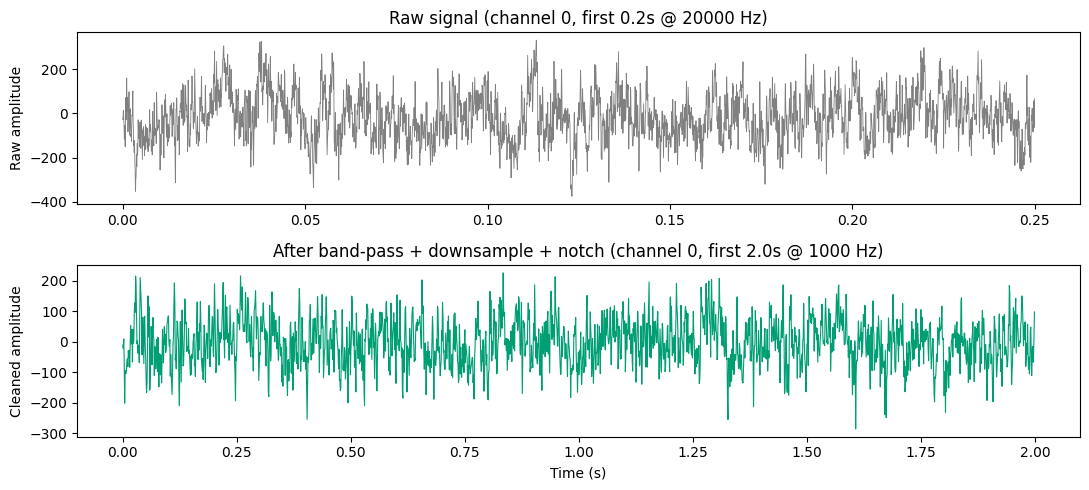

-> saved: D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13\preprocessing_example.png


In [7]:
# ===================== PREPROCESSING SANITY CHECK ============================

example_channel = 0
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=False)
t_raw = np.arange(min(5000, example_raw.shape[1])) / sf
axes[0].plot(t_raw, example_raw[example_channel, :len(t_raw)], color="gray", linewidth=0.6)
axes[0].set_title(f"Raw signal (channel {example_channel}, first {len(t_raw)/sf:.1f}s @ {sf} Hz)")
axes[0].set_ylabel("Raw amplitude")

t_clean = np.arange(min(2000, example_clean.shape[1])) / target_sf
axes[1].plot(t_clean, example_clean[example_channel, :len(t_clean)], color="#009E73", linewidth=0.8)
axes[1].set_title(f"After band-pass + downsample + notch (channel {example_channel}, "
                   f"first {len(t_clean)/target_sf:.1f}s @ {target_sf} Hz)")
axes[1].set_ylabel("Cleaned amplitude")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
fig_path = os.path.join(OUT_DIR, "preprocessing_example.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"-> saved: {fig_path}")


In [8]:
# ===================== WINDOWING: NAMED BAND POWER (replaces broadband collapse) =

from scipy.signal import welch
from numpy.lib.stride_tricks import sliding_window_view

BAND_NAMES = list(BAND_DEFINITIONS.keys())
N_BANDS = len(BAND_NAMES)


def prepare_band_features(data, window_size=WINDOW_SIZE, stride=STRIDE,
                           target_sf=target_sf, ref_channel=REFERENCE_CHANNEL,
                           bands=BAND_DEFINITIONS):
    """
    data: shape (channels, timepoints)
    Returns: band_feats, shape (n_windows, n_bands, n_channels_kept)
    """
    num_channels = data.shape[0]
    keep_channels = [c for c in range(num_channels) if c != ref_channel]
    data_kept = data[keep_channels]

    n_windows = (data_kept.shape[1] - window_size) // stride + 1
    if n_windows < 1:
        return np.empty((0, len(bands), len(keep_channels)))

    all_windows = sliding_window_view(data_kept, window_shape=window_size, axis=1)
    windows = all_windows[:, ::stride, :][:, :n_windows, :] 

    freqs, psd = welch(windows, fs=target_sf, nperseg=window_size, axis=-1)  

    band_feats = []
    for name in BAND_NAMES:
        lo, hi = bands[name]
        mask = (freqs >= lo) & (freqs < hi)
        if not mask.any():
            raise ValueError(f"Band '{name}' ({lo}-{hi} Hz) has NO frequency bins at this "
                             f"window size (resolution={target_sf/window_size:.2f} Hz). "
                             f"Increase WINDOW_SIZE or widen this band.")
        band_feats.append(np.median(psd[:, :, mask], axis=-1))  

    return np.stack(band_feats, axis=0).transpose(2, 0, 1)  


_freq_res = target_sf / WINDOW_SIZE
print(f"Frequency resolution: {_freq_res:.2f} Hz  ({WINDOW_SIZE} samples @ {target_sf}Hz)")
for name, (lo, hi) in BAND_DEFINITIONS.items():
    n_bins = int(np.floor(hi / _freq_res) - np.ceil(lo / _freq_res)) + 1
    n_bins = max(n_bins, 0)
    flag = "" if n_bins > 0 else "  *** ZERO BINS -- this band cannot be resolved! ***"
    print(f"  {name:12s} ({lo:>3}-{hi:<3} Hz): ~{n_bins} frequency bin(s){flag}")

print("\nprepare_band_features ready.")


Frequency resolution: 1.00 Hz  (1000 samples @ 1000Hz)
  theta        (  4-12  Hz): ~9 frequency bin(s)
  beta         ( 12-25  Hz): ~14 frequency bin(s)
  low_gamma    ( 30-59  Hz): ~30 frequency bin(s)
  high_gamma   ( 61-100 Hz): ~40 frequency bin(s)
  gamma        ( 30-100 Hz): ~71 frequency bin(s)
  hfo          (120-200 Hz): ~81 frequency bin(s)

prepare_band_features ready.


In [9]:
# ===================== BUILD X_all / y_all / groups_all TOGETHER ============

X_parts, y_parts, group_parts = [], [], []

for i, row in manifest_df.iterrows():
    data = cleaned_data_by_file[row["file_path"]]
    X_data = prepare_band_features(data)   
    n_windows = len(X_data)
    y_data = np.full(n_windows, LABEL_MAP[row["genotype"]])
    g_data = np.full(n_windows, row["animal_id"])

    print(f"  {os.path.basename(row['file_path'])}: {n_windows} windows "
          f"(animal={row['animal_id']}, genotype={row['genotype']})")

    X_parts.append(X_data)
    y_parts.append(y_data)
    group_parts.append(g_data)

X_all = np.concatenate(X_parts, axis=0)          
y_all = np.concatenate(y_parts, axis=0)
groups_all = np.concatenate(group_parts, axis=0)

n_channels_kept = X_all.shape[2]
print(f"\nTotal windows: {X_all.shape[0]}")
print(f"X_all shape: {X_all.shape}  (n_windows, n_bands={N_BANDS}, n_channels={n_channels_kept})")
print(f"Unique animals represented in windows: {len(np.unique(groups_all))}")


X_collapsed_all = X_all.reshape(X_all.shape[0], -1)
print(f"X_collapsed_all shape: {X_collapsed_all.shape}")


  2024-06-03__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0004.h5: 548 windows (animal=WT_06-03, genotype=WT)
  2024-06-03__Slice2_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5: 545 windows (animal=WT_06-03, genotype=WT)
  2024-06-06__Slice1_WT_mPFC_Baseline__0006.h5: 544 windows (animal=WT_06-06, genotype=WT)
  2024-06-06__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0002.h5: 544 windows (animal=WT_06-06, genotype=WT)
  2024-06-06__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5: 544 windows (animal=WT_06-06, genotype=WT)
  2024-06-11__Slice1_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5: 544 windows (animal=WT_06-11, genotype=WT)
  2024-06-11__Slice2_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0005.h5: 544 windows (animal=WT_06-11, genotype=WT)
  2024-06-11__Slice3_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5: 544 windows (animal=WT_06-11, genotype=WT)
  2024-06-11__Slice4_WT_S5E2_Chr2_eYFP_mPFC_Baseline__0003.h5: 544 windows (animal=WT_06-11, genotype=WT)
  2024-07-09mPFC_Slice2_LC_to_mPFC_CAG_ChR2_eYFP_10Second_Stim_WT_V

In [10]:
# ===================== MODEL ZOO -- all 7 architectures from your notebook ===

# GPU-fast), L2, and the reduced Dense width instead.
L2_REG = tf.keras.regularizers.l2(1e-4)
SEARCH_SPACE = {
    "learning_rate":[1e-3,1e-4],
    "activation":["relu","gelu", "swish"],
    "dense_units":[64,128],
    "dropout":[0.5,0.7],
    "l2_reg":[1e-4],
    "optimizer":["adam", "sgd"]  
}
def activation_layer(name):

    if name == "leakyrelu":
        return layers.LeakyReLU()

    elif name == "gelu":
        return layers.Activation("gelu")

    elif name == "swish":
        return layers.Activation("swish")

    elif name == "elu":
        return layers.ELU()

    elif name == "relu":
        return layers.ReLU()

    else:
        raise ValueError(f"Unknown activation: {name}")
def build_rnn(
        input_shape,
        learning_rate=1e-3,
        activation="relu",
        dense_units=128,
        dropout=0.5,
        l2_reg=1e-4,
        optimizer="adam"):

    reg = tf.keras.regularizers.l2(l2_reg)

    m = models.Sequential([
        layers.Input(shape=input_shape),

        layers.LSTM(64, return_sequences=True),
        layers.Dropout(dropout),

        layers.LSTM(128),
        layers.Dropout(dropout),

        layers.Dense(
            dense_units,
            activation=activation,
            kernel_regularizer=reg
        ),

        layers.Dropout(dropout),

        layers.Dense(3, activation="softmax", dtype="float32")
    ])

    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer}")

    m.compile(opt,
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

    return m


def build_birnn(
        input_shape,
        learning_rate=1e-3,
        activation="relu",
        dense_units=128,
        dropout=0.5,
        l2_reg=1e-4,
        optimizer="adam"):

    reg = tf.keras.regularizers.l2(l2_reg)

    m = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Bidirectional(
            layers.LSTM(64, return_sequences=True)
        ),

        layers.Dropout(dropout),

        layers.Bidirectional(
            layers.LSTM(128)
        ),

        layers.Dropout(dropout),

        layers.Dense(dense_units,
                     kernel_regularizer=reg),

        activation_layer(activation),

        layers.Dropout(dropout),

        layers.Dense(3, activation="softmax", dtype="float32")
    ])

    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer}")

    m.compile(opt,
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

    return m


def build_gru_rnn(
        input_shape,
        learning_rate=1e-3,
        activation="relu",
        dense_units=128,
        dropout=0.5,
        l2_reg=1e-4,
        optimizer="adam"):

    reg = tf.keras.regularizers.l2(l2_reg)

    m = models.Sequential([
        layers.Input(shape=input_shape),

        layers.GRU(64, return_sequences=True),
        layers.Dropout(dropout),

        layers.GRU(128),
        layers.Dropout(dropout),

        layers.Dense(dense_units,
                     kernel_regularizer=reg),

        activation_layer(activation),

        layers.Dropout(dropout),

        layers.Dense(3,
                     activation="softmax",
                     dtype="float32")
    ])

    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer}")

    m.compile(opt,
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

    return m


def build_cnn_lstm(
        input_shape,
        learning_rate=1e-3,
        activation="relu",
        dense_units=128,
        dropout=0.5,
        l2_reg=1e-4,
        optimizer="adam"):

    reg = tf.keras.regularizers.l2(l2_reg)

    m = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv1D(
            64,
            3,
            activation=activation
        ),

        layers.MaxPooling1D(),

        layers.LSTM(128),

        layers.Dropout(dropout),

        layers.Dense(dense_units,
                     kernel_regularizer=reg),

        activation_layer(activation),

        layers.Dropout(dropout),

        layers.Dense(3,
                     activation="softmax",
                     dtype="float32")
    ])

    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer}")

    m.compile(opt,
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

    return m




def _positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, np.newaxis]
    i = np.arange(d_model)[np.newaxis, :]
    angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
    angle_rads = pos * angle_rates
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    return tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)




def build_cnn(
        input_shape,
        learning_rate=1e-3,
        activation="relu",
        dense_units=128,
        dropout=0.5,
        l2_reg=1e-4,
        optimizer="adam"):

    reg = tf.keras.regularizers.l2(l2_reg)

    m = models.Sequential([

        layers.Input(shape=input_shape),


        layers.Conv2D(
            64,
            (3,3),
            padding="same",
            activation=None
        ),

        activation_layer(activation),

        layers.MaxPooling2D(pool_size=(2,1)),

        layers.Dropout(dropout),


        layers.Conv2D(
            128,
            (3,3),
            padding="same",
            activation=None
        ),

        activation_layer(activation),

        layers.MaxPooling2D(pool_size=(2,1)),

        layers.Dropout(dropout),


        layers.Conv2D(
            256,
            (3,3),
            padding="same",
            activation=None
        ),

        activation_layer(activation),

        layers.MaxPooling2D(pool_size=(2,1)),

        layers.Dropout(dropout),


        layers.Flatten(),


        layers.Dense(
            dense_units,
            kernel_regularizer=reg
        ),

        activation_layer(activation),

        layers.Dropout(dropout),


        layers.Dense(
            3,
            activation="softmax",
            dtype="float32"
        )

    ])


    if optimizer == "adam":
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer}")


    m.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return m


MODEL_ZOO = {
    "RNN":      (build_rnn,      "rnn", (N_BANDS, n_channels_kept)),
    "BiRNN":    (build_birnn,    "rnn", (N_BANDS, n_channels_kept)),
    "GRU-RNN":  (build_gru_rnn,  "rnn", (N_BANDS, n_channels_kept)),
    "CNN_LSTM": (build_cnn_lstm, "rnn", (N_BANDS, n_channels_kept)),
    "CNN":      (build_cnn,      "cnn", (n_channels_kept, N_BANDS, 1)),
}
MODELS_TO_RUN = ["RNN", "BiRNN", "GRU-RNN", "CNN_LSTM", "CNN"]
print("Model zoo ready:", list(MODEL_ZOO.keys()))
print("Will actually run (per MODELS_TO_RUN):", MODELS_TO_RUN)


Model zoo ready: ['RNN', 'BiRNN', 'GRU-RNN', 'CNN_LSTM', 'CNN']
Will actually run (per MODELS_TO_RUN): ['RNN', 'BiRNN', 'GRU-RNN', 'CNN_LSTM', 'CNN']


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from itertools import product

VALIDATION_ANIMAL_FRACTION = 0.3  # fraction of TRAINING animals held out (at animal
                                  # level, never touching the test animal) purely for
                                  # early stopping / LR scheduling.

def split_off_validation_animals(train_idx, groups_all, y_all, seed=0):
    """Stratified by genotype: with few animals per class, a naive random
       split can take the ONLY remaining training animal of some genotype,
       leaving that class completely absent from the fit set. Always keeps
       at least 1 fit-animal per genotype that has any training animals."""
    rng = np.random.default_rng(seed)
    train_animals = np.unique(groups_all[train_idx])
    animal_to_label = {a: y_all[train_idx][groups_all[train_idx] == a][0] for a in train_animals}
    val_animals = set()
    for label in np.unique(list(animal_to_label.values())):
        animals_this_label = [a for a, l in animal_to_label.items() if l == label]
        rng.shuffle(animals_this_label)
        n_val = int(round(len(animals_this_label) * VALIDATION_ANIMAL_FRACTION))
        n_val = min(n_val, max(0, len(animals_this_label) - 1))
        val_animals.update(animals_this_label[:n_val])
    is_val = np.isin(groups_all[train_idx], list(val_animals))
    return train_idx[~is_val], train_idx[is_val]


def standardize_fold(collapsed, fit_idx, *idx_sets):
    """Fit StandardScaler on collapsed[fit_idx] (TRAINING windows only -- no
       leakage) and transform every provided index set with those stats.
       collapsed is (n_windows, n_bands*n_channels) -- every value here is a
       genuinely distinct band-power reading (no repeated-timestep
       redundancy, unlike the old broadband-scalar version)."""
    scaler = StandardScaler()
    scaler.fit(collapsed[fit_idx])
    return [scaler.transform(collapsed[idx]) for idx in idx_sets]


def expand_to_rnn(collapsed_subset):
    # (n, n_bands*n_channels) -> (n, n_bands, n_channels): bands as the
    # timestep axis, a real ordered sequence (low->high frequency).
    return collapsed_subset.reshape(-1, N_BANDS, n_channels_kept)


def expand_to_cnn(collapsed_subset):
    rnn_shaped = expand_to_rnn(collapsed_subset)                # (n, n_bands, n_channels)
    return rnn_shaped.transpose(0, 2, 1)[..., np.newaxis]       # (n, n_channels, n_bands, 1)


if os.path.exists(RESULTS_CSV):
    existing_results = pd.read_csv(RESULTS_CSV)
    done_pairs = set(zip(existing_results["animal_id"], existing_results["model_name"]))
    print(f"Resuming: {len(done_pairs)} (animal, model) pair(s) already completed, will be skipped.")
else:
    existing_results = pd.DataFrame(columns=[
        "animal_id", "model_name", "true_genotype", "n_windows",
        "window_level_accuracy", "window_level_f1_macro",
        "majority_vote_pred", "majority_vote_correct", "best_params",
    ])
    done_pairs = set()

logo = LeaveOneGroupOut()
all_folds = list(logo.split(X_all, y_all, groups_all))
print(f"Total animals: {len(all_folds)}  x  models: {len(MODELS_TO_RUN)} "
      f"= {len(all_folds)*len(MODELS_TO_RUN)} total (animal, model) evaluations")


# ===================== HYPERPARAMETER SEARCH -- ONCE PER MODEL =====================
# Doing the full SEARCH_SPACE grid inside every one of the 115 (animal,
# model) folds would be 23 x 5 x len(grid) full model trainings --
# thousands of runs, computationally infeasible (this was the main reason
# the previous version never finished). Trade-off made here: tune each
# architecture's hyperparameters ONCE, using a single representative
# animal-level train/dev split (built the same stratified-by-genotype way
# as the per-fold validation split), then FREEZE those best hyperparameters
# and reuse them across all 23 LOGO folds for that architecture. This is
# less rigorous than nested CV (which retunes inside every outer fold) but
# is standard practice given deep learning training costs, and is roughly
# a 23x reduction in total training runs versus per-fold search.
print("\n=== Hyperparameter search (once per architecture) ===")
all_animals = np.unique(groups_all)
rng_tune = np.random.default_rng(0)
tune_train_idx, tune_val_idx = split_off_validation_animals(
    np.arange(len(y_all)), groups_all, y_all, seed=999)

X_tune_fit_c, X_tune_val_c = standardize_fold(X_collapsed_all, tune_train_idx, tune_train_idx, tune_val_idx)
y_tune_fit, y_tune_val = y_all[tune_train_idx], y_all[tune_val_idx]
tune_class_weights = compute_class_weight("balanced", classes=np.array([0,1,2]), y=y_tune_fit)
tune_class_weight_dict = {int(i): float(w) for i, w in enumerate(tune_class_weights)}

BEST_PARAMS_PER_MODEL = {}
search_keys = list(SEARCH_SPACE.keys())

for model_name in MODELS_TO_RUN:
    builder, array_kind, input_shape = MODEL_ZOO[model_name]
    expand_fn = expand_to_rnn if array_kind == "rnn" else expand_to_cnn
    X_tune_fit = expand_fn(X_tune_fit_c)
    X_tune_val = expand_fn(X_tune_val_c)

    print(f"\n[{model_name}] searching {len(list(product(*SEARCH_SPACE.values())))} combinations...")
    best_val_acc, best_params = -np.inf, None
    for values in product(*SEARCH_SPACE.values()):
        params = dict(zip(search_keys, values))
        tf.keras.backend.clear_session()
        model = builder(input_shape=input_shape, **params)
        history = model.fit(
            X_tune_fit, y_tune_fit, validation_data=(X_tune_val, y_tune_val),
            epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, class_weight=tune_class_weight_dict,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
        )
        score = max(history.history["val_accuracy"])
        if score > best_val_acc:
            best_val_acc, best_params = score, params.copy()
            print(f"  NEW BEST: {best_params}  score={best_val_acc:.4f}")

    BEST_PARAMS_PER_MODEL[model_name] = best_params
    print(f"[{model_name}] FINAL BEST: {best_params}  (val_acc={best_val_acc:.4f})")

print("\nBEST_PARAMS_PER_MODEL:", BEST_PARAMS_PER_MODEL)


# ===================== LEAVE-ONE-ANIMAL-OUT (frozen hyperparameters) =====================
for fold_i, (train_idx, test_idx) in enumerate(all_folds):
    held_out_animal = groups_all[test_idx][0]
    true_label_int = y_all[test_idx][0]
    true_genotype = INV_LABEL_MAP[true_label_int]

    assert held_out_animal not in set(groups_all[train_idx]), (
        f"LEAKAGE: {held_out_animal} appears in both train and test!")

    fit_idx, val_idx = split_off_validation_animals(train_idx, groups_all, y_all, seed=fold_i)
    assert held_out_animal not in set(groups_all[val_idx])
    assert len(set(groups_all[fit_idx]) & set(groups_all[val_idx])) == 0

    y_fit, y_val, y_te = y_all[fit_idx], y_all[val_idx], y_all[test_idx]
    class_weights = compute_class_weight("balanced", classes=np.array([0,1,2]), y=y_fit)
    class_weight_dict = {int(i): float(w) for i, w in enumerate(class_weights)}

    for model_name in MODELS_TO_RUN:
        if (held_out_animal, model_name) in done_pairs:
            continue

        builder, array_kind, input_shape = MODEL_ZOO[model_name]
        expand_fn = expand_to_rnn if array_kind == "rnn" else expand_to_cnn
        best_params = BEST_PARAMS_PER_MODEL[model_name]

        has_val = len(val_idx) > 0
        if has_val:
            X_fit_c, X_val_c, X_te_c = standardize_fold(X_collapsed_all, fit_idx, fit_idx, val_idx, test_idx)
            X_val = expand_fn(X_val_c)
        else:
            X_fit_c, X_te_c = standardize_fold(X_collapsed_all, fit_idx, fit_idx, test_idx)
        X_tr = expand_fn(X_fit_c)
        X_te = expand_fn(X_te_c)

        print(f"\n[animal {fold_i+1}/{len(all_folds)} | {model_name}] held-out={held_out_animal} "
              f"(true={true_genotype}, fit={len(fit_idx)}, val={len(val_idx)}, test={len(test_idx)})")

        tf.keras.backend.clear_session()
        model = builder(input_shape=input_shape, **best_params)
        if has_val:
            model.fit(
                X_tr, y_fit, validation_data=(X_val, y_val),
                epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, class_weight=class_weight_dict,
                callbacks=[
                    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=5, factor=0.5, min_lr=1e-6),
                ],
            )
        else:
            model.fit(
                X_tr, y_fit, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, class_weight=class_weight_dict,
                callbacks=[tf.keras.callbacks.EarlyStopping(monitor="loss", patience=10, restore_best_weights=True)],
            )

        y_pred_proba = model.predict(X_te, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)
        window_acc = accuracy_score(y_te, y_pred)
        window_f1 = f1_score(y_te, y_pred, average="macro", zero_division=0)
        majority_vote = int(np.bincount(y_pred, minlength=3).argmax())
        majority_correct = (majority_vote == true_label_int)

        print(f"RESULT | window acc={window_acc:.3f} | majority={INV_LABEL_MAP[majority_vote]} "
              f"{'CORRECT' if majority_correct else 'WRONG'}")

        new_row = pd.DataFrame([dict(
            animal_id=held_out_animal, model_name=model_name, true_genotype=true_genotype,
            n_windows=len(test_idx), window_level_accuracy=window_acc, window_level_f1_macro=window_f1,
            majority_vote_pred=INV_LABEL_MAP[majority_vote], majority_vote_correct=majority_correct,
            best_params=str(best_params),
        )])
        existing_results = pd.concat([existing_results, new_row], ignore_index=True)
        existing_results.to_csv(RESULTS_CSV, index=False)

print(f"\nDONE. {len(existing_results)} results saved to {RESULTS_CSV}")


Resuming: 115 (animal, model) pair(s) already completed, will be skipped.
Total animals: 23  x  models: 5 = 115 total (animal, model) evaluations

=== Hyperparameter search (once per architecture) ===

[RNN] searching 48 combinations...
  NEW BEST: {'learning_rate': 0.001, 'activation': 'relu', 'dense_units': 64, 'dropout': 0.5, 'l2_reg': 0.0001, 'optimizer': 'adam'}  score=0.2795
  NEW BEST: {'learning_rate': 0.001, 'activation': 'relu', 'dense_units': 64, 'dropout': 0.5, 'l2_reg': 0.0001, 'optimizer': 'sgd'}  score=0.3292
  NEW BEST: {'learning_rate': 0.001, 'activation': 'relu', 'dense_units': 64, 'dropout': 0.7, 'l2_reg': 0.0001, 'optimizer': 'sgd'}  score=0.3353
  NEW BEST: {'learning_rate': 0.001, 'activation': 'relu', 'dense_units': 128, 'dropout': 0.5, 'l2_reg': 0.0001, 'optimizer': 'sgd'}  score=0.3362
  NEW BEST: {'learning_rate': 0.001, 'activation': 'relu', 'dense_units': 128, 'dropout': 0.7, 'l2_reg': 0.0001, 'optimizer': 'sgd'}  score=0.3538
  NEW BEST: {'learning_rate': 

=== Overall summary by model ===
model_name  n_animals  mean_window_accuracy  animal_level_accuracy
     BiRNN         23              0.421531               0.478261
   GRU-RNN         23              0.406770               0.478261
       RNN         23              0.378053               0.391304
       CNN         23              0.348430               0.304348
  CNN_LSTM         23              0.286534               0.260870


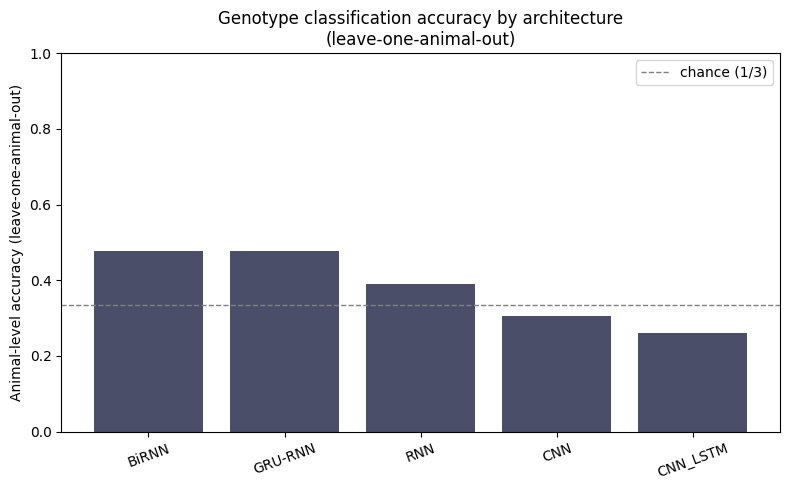


-> saved: D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13\LOGO_CV_model_comparison.png


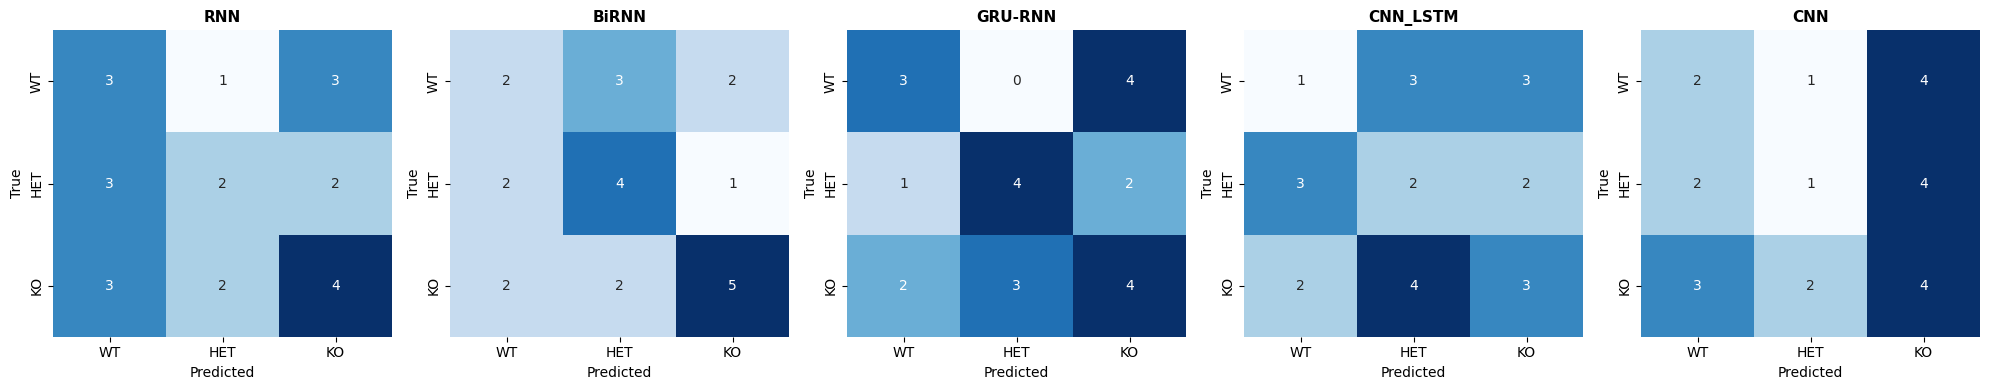

-> saved: D:\UMICH\Deep_Learning\CNN_samples\ML_Samples\LOGO_CV_Results_V13\LOGO_CV_confusion_matrices.png


In [14]:
# ===================== AGGREGATE RESULTS + PLOTS =============================
results_df = pd.read_csv(RESULTS_CSV)
results_df["true_genotype"] = pd.Categorical(results_df["true_genotype"], categories=["WT", "HET", "KO"])

print("=== Overall summary by model ===")
summary = results_df.groupby("model_name").agg(
    n_animals=("animal_id", "nunique"),
    mean_window_accuracy=("window_level_accuracy", "mean"),
    animal_level_accuracy=("majority_vote_correct", "mean"),
).reset_index().sort_values("animal_level_accuracy", ascending=False)
print(summary.to_string(index=False))

# --- Grouped bar: animal-level accuracy per model, chance line at 1/3 -------
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(summary["model_name"], summary["animal_level_accuracy"], color="#4A4E69")
ax.axhline(1/3, color="gray", linestyle="--", linewidth=1, label="chance (1/3)")
ax.set_ylabel("Animal-level accuracy (leave-one-animal-out)")
ax.set_ylim(0, 1)
ax.set_title("Genotype classification accuracy by architecture\n(leave-one-animal-out)")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
fig_path = os.path.join(OUT_DIR, "LOGO_CV_model_comparison.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.savefig(fig_path.replace(".png", ".svg"), bbox_inches="tight")
plt.show()
print(f"\n-> saved: {fig_path}")

# --- Confusion matrix per model (majority-vote, animal level) ---------------
GENOTYPE_ORDER = ["WT", "HET", "KO"]
models_present = results_df["model_name"].unique().tolist()
n_m = len(models_present)
fig2, axes2 = plt.subplots(1, n_m, figsize=(4*n_m, 4), squeeze=False)
axes2 = axes2[0]
for ax, model_name in zip(axes2, models_present):
    sub = results_df[results_df["model_name"] == model_name]
    cm = confusion_matrix(sub["true_genotype"], sub["majority_vote_pred"], labels=GENOTYPE_ORDER)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=GENOTYPE_ORDER,
                yticklabels=GENOTYPE_ORDER, ax=ax, cbar=False)
    ax.set_title(model_name, fontsize=11, weight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
fig2_path = os.path.join(OUT_DIR, "LOGO_CV_confusion_matrices.png")
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"-> saved: {fig2_path}")


In [13]:
OUT_DIR

'D:\\UMICH\\Deep_Learning\\CNN_samples\\ML_Samples\\LOGO_CV_Results_V13'

classes in held-out animals: ['WT', 'HET', 'KO']
majority-class chance = 0.391
model_name  n_animals  animal_level_accuracy  animal_lo  animal_hi  mean_window_accuracy  window_sem
     BiRNN         23                  0.478      0.261      0.696                 0.422       0.085
   GRU-RNN         23                  0.478      0.261      0.696                 0.407       0.072
       RNN         23                  0.391      0.217      0.609                 0.378       0.070
       CNN         23                  0.304      0.130      0.478                 0.348       0.086
  CNN_LSTM         23                  0.261      0.087      0.478                 0.287       0.072


C:\Users\sh2075\AppData\Local\Temp\ipykernel_57304\395338477.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub, x="model_name", y="window_level_accuracy", order=order,


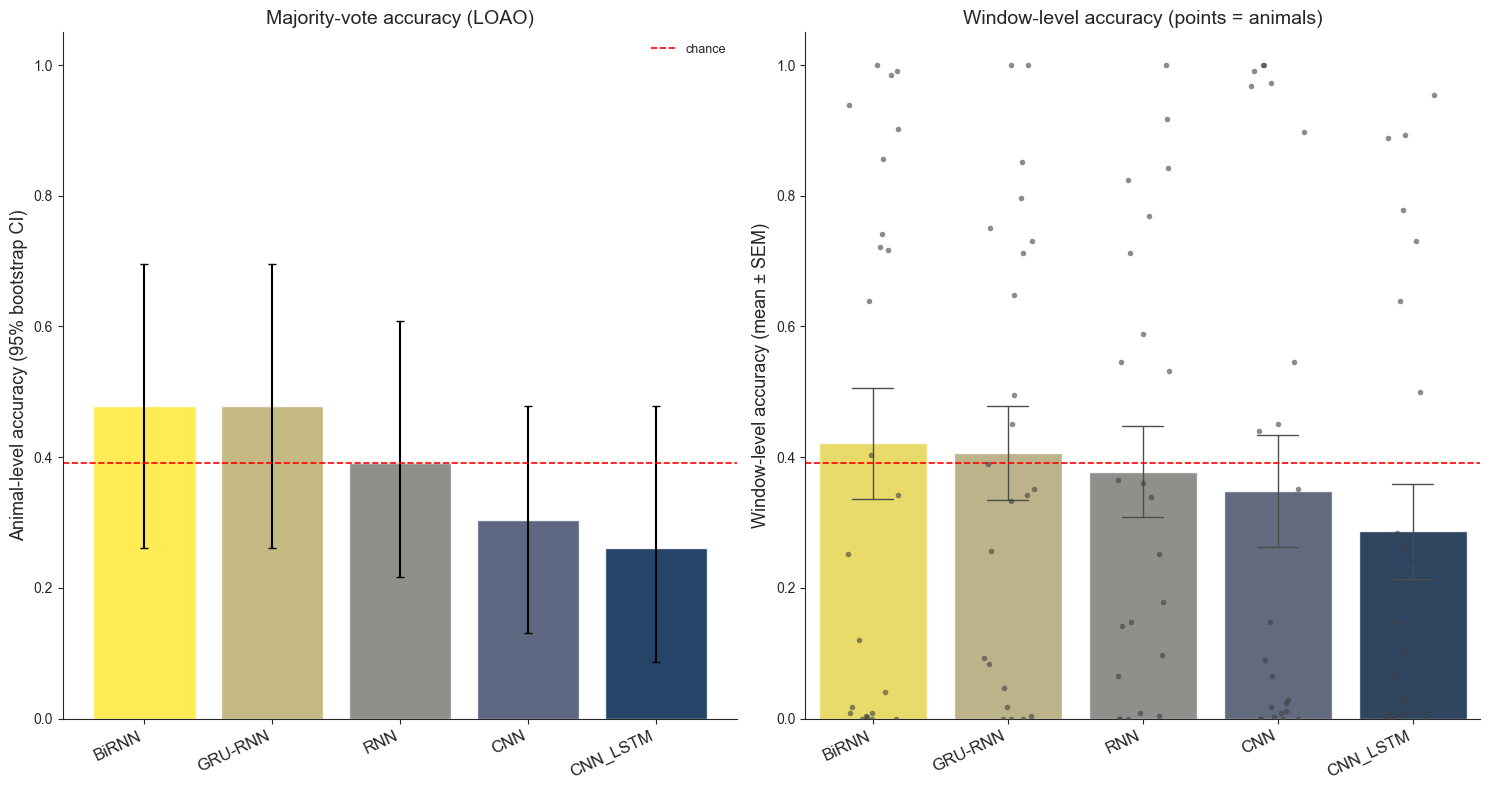

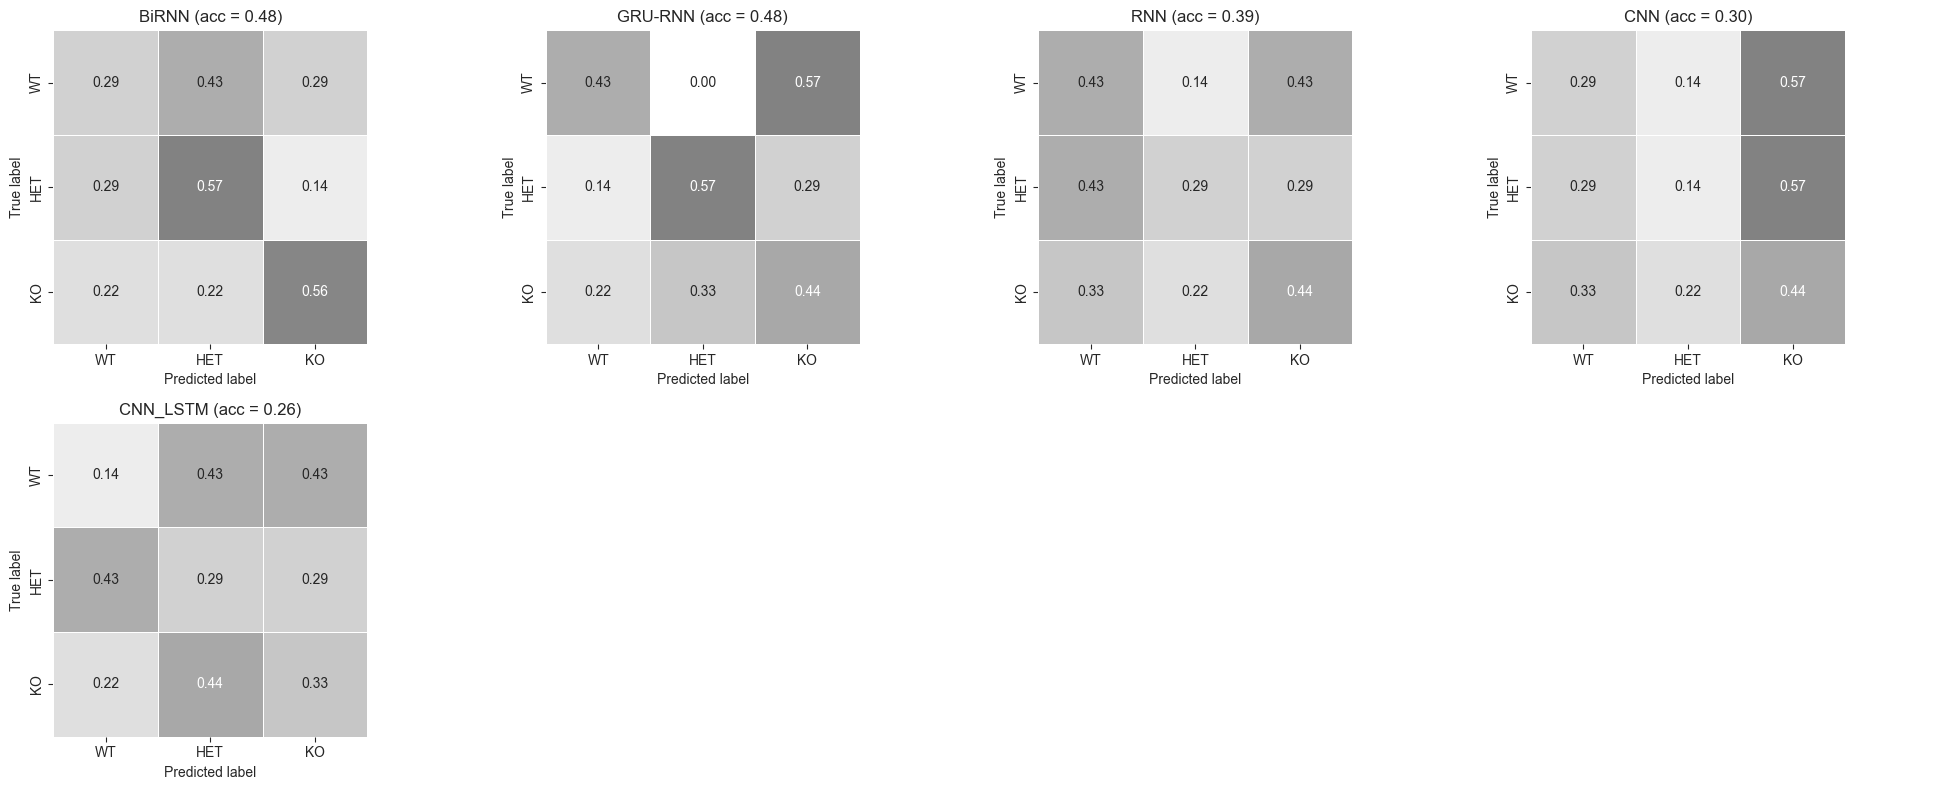

In [18]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.cm as cm_mpl, seaborn as sns
from sklearn.metrics import confusion_matrix

OUT_DIR = r"D:\\UMICH\\Deep_Learning\\CNN_samples\\ML_Samples\\LOGO_CV_Results_V13"
RESULTS_CSV = os.path.join(OUT_DIR, "per_animal_per_model_LOGO_results.csv")
N_BOOT = 5000
rng = np.random.default_rng(0)

results_df = pd.read_csv(RESULTS_CSV)
GEN = [g for g in ["WT", "HET", "KO"] if g in set(results_df.true_genotype)]
results_df["true_genotype"] = pd.Categorical(results_df.true_genotype, categories=GEN)
print("classes in held-out animals:", GEN)

rows = []
for m, g in results_df.groupby("model_name"):
    n = g.animal_id.nunique(); p = g.majority_vote_correct.mean()
    boot = rng.binomial(n, p, N_BOOT) / n              # CI on the proportion
    rows.append(dict(model_name=m, n_animals=n,
        animal_level_accuracy=p,
        animal_lo=np.percentile(boot, 2.5), animal_hi=np.percentile(boot, 97.5),
        mean_window_accuracy=g.window_level_accuracy.mean(),
        window_sem=g.window_level_accuracy.std(ddof=1)/np.sqrt(n)))
summary = pd.DataFrame(rows).sort_values("animal_level_accuracy", ascending=False)

# EMPIRICAL chance = majority class among held-out animals, NOT 1/3
chance = (results_df.groupby("true_genotype", observed=True).animal_id.nunique().max()
          / results_df.animal_id.nunique())
print(f"majority-class chance = {chance:.3f}")
print(summary.round(3).to_string(index=False))

# ---- same look as the machine-learning figures
order = summary.model_name.tolist(); x = np.arange(len(order))
colors = cm_mpl.cividis_r(np.linspace(0, 1, len(order)))
model_colors = dict(zip(order, colors))

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# --- animal-level, bootstrap CI ---
ax = axes[0]
err = np.vstack([summary.animal_level_accuracy - summary.animal_lo,
                 summary.animal_hi - summary.animal_level_accuracy])
ax.bar(x, summary.animal_level_accuracy, color=colors, alpha=.85,
       yerr=err, capsize=3)
ax.axhline(chance, ls="--", color="red", lw=1.2, label="chance")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=25, ha="right", fontsize=12)
ax.set_ylabel("Animal-level accuracy (95% bootstrap CI)", fontsize=13)
ax.set_ylim(0, 1.05)
ax.set_title("Majority-vote accuracy (LOAO)", fontsize=14)
ax.legend(frameon=False, fontsize=9)

# --- window-level, SEM across animals + individual animals ---
ax = axes[1]
sub = results_df.copy()
sub["model_name"] = pd.Categorical(sub.model_name, categories=order, ordered=True)
sns.barplot(data=sub, x="model_name", y="window_level_accuracy", order=order,
            palette=model_colors, alpha=.85, errorbar="se", capsize=.3,
            err_kws=dict(lw=1, color="0.3"), ax=ax)
sns.stripplot(data=sub, x="model_name", y="window_level_accuracy", order=order,
              color="0.25", size=4, alpha=.6, jitter=.2, ax=ax)
ax.axhline(chance, ls="--", color="red", lw=1.2)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha="right", fontsize=12)
ax.set_xlabel(""); ax.set_ylabel("Window-level accuracy (mean ± SEM)", fontsize=13)
ax.set_ylim(0, 1.05)
ax.set_title("Window-level accuracy (points = animals)", fontsize=14)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_model_comparison.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_model_comparison.svg"), bbox_inches="tight")
plt.show()

# --- confusion matrices: colour normalized, counts annotated ---
n_m = len(order)
n_cols = 4
n_rows = (n_m + n_cols - 1) // n_cols
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes2 = np.atleast_1d(axes2).flatten()
for ax, m in zip(axes2, order):
    s = results_df[results_df.model_name == m]
    cm = confusion_matrix(s.true_genotype, s.majority_vote_pred, labels=GEN)
    cmn = cm.astype(float) / np.clip(cm.sum(1, keepdims=True), 1, None)
    sns.heatmap(cmn, annot=cmn, fmt=".2f", cmap="Greys", vmin=0, vmax=1,
                xticklabels=GEN, yticklabels=GEN, ax=ax, cbar=False,
                linewidths=.5, linecolor="white", square=True)
    ax.set_title(f"{m} (acc = {s.majority_vote_correct.mean():.2f})", fontsize=12)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
for j in range(n_m, len(axes2)):
    axes2[j].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_confusion_matrices.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_confusion_matrices.svg"), bbox_inches="tight")
plt.show()

In [2]:
print(results_df.groupby("model_name").window_level_f1_macro.agg(["mean", "sem"]).round(3))

             mean    sem
model_name              
BiRNN       0.204  0.049
CNN         0.218  0.062
CNN_LSTM    0.130  0.030
GRU-RNN     0.236  0.056
RNN         0.198  0.046


classes in held-out animals: ['WT', 'HET', 'KO']
majority-class chance = 0.391
model_name  n_animals  animal_level_accuracy  animal_sem  animal_lo  animal_hi  mean_window_accuracy  window_sem
     BiRNN         23                  0.478       0.106      0.261      0.696                 0.422       0.085
   GRU-RNN         23                  0.478       0.106      0.261      0.696                 0.407       0.072
       RNN         23                  0.391       0.104      0.217      0.609                 0.378       0.070
       CNN         23                  0.304       0.098      0.130      0.478                 0.348       0.086
  CNN_LSTM         23                  0.261       0.094      0.087      0.478                 0.287       0.072


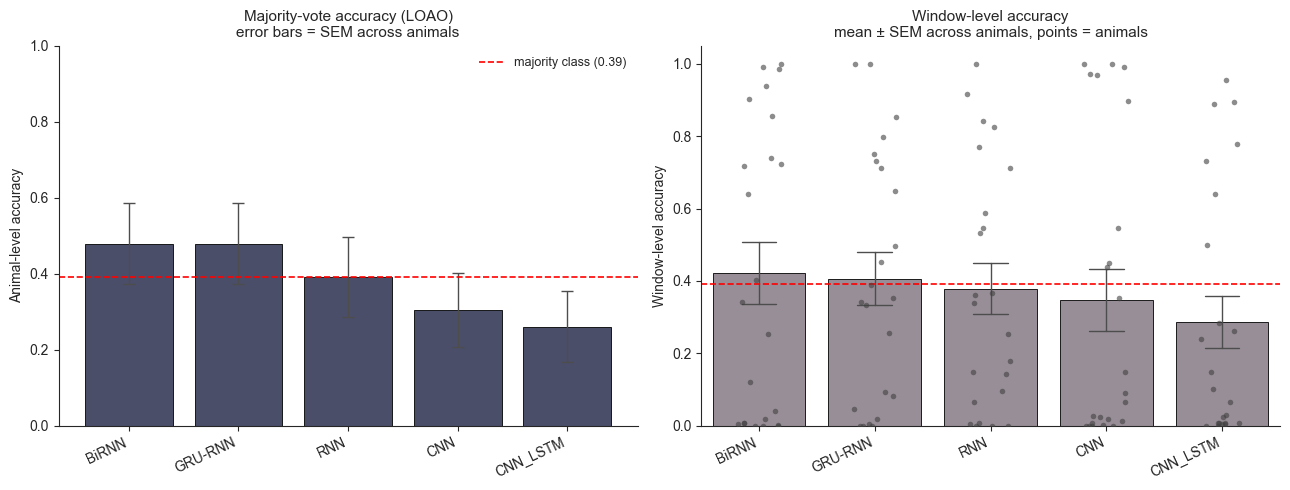

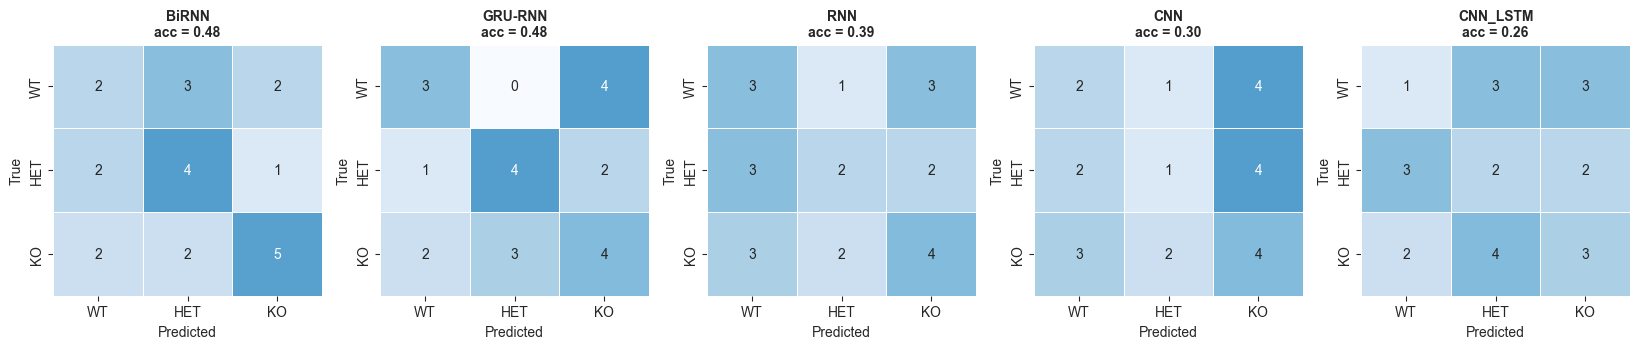

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

OUT_DIR = r"D:\\UMICH\\Deep_Learning\\CNN_samples\\ML_Samples\\LOGO_CV_Results_V13"
RESULTS_CSV = os.path.join(OUT_DIR, "per_animal_per_model_LOGO_results.csv")
N_BOOT = 5000
rng = np.random.default_rng(0)

results_df = pd.read_csv(RESULTS_CSV)
GEN = [g for g in ["WT", "HET", "KO"] if g in set(results_df.true_genotype)]
results_df["true_genotype"] = pd.Categorical(results_df.true_genotype, categories=GEN)
print("classes in held-out animals:", GEN)

rows = []
for m, g in results_df.groupby("model_name"):
    n = g.animal_id.nunique(); p = g.majority_vote_correct.mean()
    boot = rng.binomial(n, p, N_BOOT) / n              # CI on the proportion
    rows.append(dict(model_name=m, n_animals=n,
        animal_level_accuracy=p,
        animal_sem=g.majority_vote_correct.astype(float).std(ddof=1) / np.sqrt(n),
        animal_lo=np.percentile(boot, 2.5), animal_hi=np.percentile(boot, 97.5),
        mean_window_accuracy=g.window_level_accuracy.mean(),
        window_sem=g.window_level_accuracy.std(ddof=1)/np.sqrt(n)))
summary = pd.DataFrame(rows).sort_values("animal_level_accuracy", ascending=False)

# EMPIRICAL chance = majority class among held-out animals, NOT 1/3
chance = (results_df.groupby("true_genotype", observed=True).animal_id.nunique().max()
          / results_df.animal_id.nunique())
print(f"majority-class chance = {chance:.3f}")
print(summary.round(3).to_string(index=False))

sns.set_style("ticks")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = summary.model_name.tolist(); x = np.arange(len(order))

# --- animal-level, SEM across animals ---
ax = axes[0]
ax.bar(x, summary.animal_level_accuracy, color="#4A4E69", edgecolor="black", lw=.6,
       yerr=summary.animal_sem, capsize=4, error_kw=dict(lw=1, ecolor="0.3"))
ax.axhline(chance, color="red", ls="--", lw=1.2, label=f"majority class ({chance:.2f})")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=25, ha="right")
ax.set_ylabel("Animal-level accuracy"); ax.set_ylim(0, 1)
ax.set_title("Majority-vote accuracy (LOAO)\nerror bars = SEM across animals", fontsize=11)
ax.legend(frameon=False, fontsize=9)

# --- window-level, SEM across animals + individual animals ---
ax = axes[1]
sub = results_df.copy()
sub["model_name"] = pd.Categorical(sub.model_name, categories=order, ordered=True)
sns.barplot(data=sub, x="model_name", y="window_level_accuracy", order=order,
            color="#9A8C98", errorbar="se", capsize=.3,
            err_kws=dict(lw=1, color="0.3"), ax=ax, edgecolor="black", linewidth=.6)
sns.stripplot(data=sub, x="model_name", y="window_level_accuracy", order=order,
              color="0.25", size=4, alpha=.6, jitter=.2, ax=ax)
ax.axhline(chance, color="red", ls="--", lw=1.2)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha="right")
ax.set_xlabel(""); ax.set_ylabel("Window-level accuracy"); ax.set_ylim(0, 1.05)
ax.set_title("Window-level accuracy\nmean ± SEM across animals, points = animals", fontsize=11)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_model_comparison.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_model_comparison.svg"), bbox_inches="tight")
plt.show()

# --- confusion matrices: colour normalized, counts annotated ---
n_m = len(order)
fig2, axes2 = plt.subplots(1, n_m, figsize=(3.3*n_m, 3.6), squeeze=False)
for ax, m in zip(axes2[0], order):
    s = results_df[results_df.model_name == m]
    cm = confusion_matrix(s.true_genotype, s.majority_vote_pred, labels=GEN)
    cmn = cm.astype(float) / np.clip(cm.sum(1, keepdims=True), 1, None)
    sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=GEN, yticklabels=GEN, ax=ax, cbar=False,
                linewidths=.5, linecolor="white")
    ax.set_title(f"{m}\nacc = {s.majority_vote_correct.mean():.2f}",
                 fontsize=10, weight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_confusion_matrices.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "LOGO_CV_confusion_matrices.svg"), bbox_inches="tight")
plt.show()